In [1]:
#target -> state factor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/WiDS Dataton.csv')

In [3]:
df.head()

,Year_Factor,State_Factor,building_class,facility_type,floor_area,year_built,energy_star_rating,ELEVATION,january_min_temp,january_avg_temp,...,december_min_temp,days_below_10F,days_below_0F,days_above_80F,direction_max_wind_speed,direction_peak_wind_speed,max_wind_speed,days_with_fog,site_eui,id
0,1,State_1,Commercial,Grocery_store_or_food_market,61242.0,1942.0,11.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,NaN,248.682615,0
1,1,State_1,Commercial,Warehouse_Distribution_or_Shipping_center,274000.0,1955.0,45.0,1.8,36,50.5,...,36,0,0,14,1.0,NaN,1.0,12.0,26.500150,1
2,1,State_1,Commercial,Retail_Enclosed_mall,280025.0,1951.0,97.0,1.8,36,50.5,...,36,0,0,14,1.0,NaN,1.0,12.0,24.693619,2
3,1,State_1,Commercial,Education_Other_classroom,55325.0,1980.0,46.0,1.8,36,50.5,...,36,0,0,14,1.0,NaN,1.0,12.0,48.406926,3
4,1,State_1,Commercial,Warehouse_Nonrefrigerated,66000.0,1985.0,100.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,NaN,3.899395,4


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31107 entries, 0 to 31106
Data columns (total 41 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Year_Factor                31107 non-null  int64  
 1   State_Factor               31107 non-null  object 
 2   building_class             31107 non-null  object 
 3   facility_type              31107 non-null  object 
 4   floor_area                 31107 non-null  float64
 5   year_built                 29614 non-null  float64
 6   energy_star_rating         14502 non-null  float64
 7   ELEVATION                  31107 non-null  float64
 8   january_min_temp           31107 non-null  int64  
 9   january_avg_temp           31107 non-null  float64
 10  january_max_temp           31107 non-null  int64  
 11  february_min_temp          31107 non-null  int64  
 12  february_avg_temp          31107 non-null  float64
 13  february_max_temp          31107 non-null  int

In [5]:
df.describe()

,Year_Factor,floor_area,year_built,energy_star_rating,ELEVATION,january_min_temp,january_avg_temp,january_max_temp,february_min_temp,february_avg_temp,...,december_min_temp,days_below_10F,days_below_0F,days_above_80F,direction_max_wind_speed,direction_peak_wind_speed,max_wind_speed,days_with_fog,site_eui,id
count,31107.000000,3.110700e+04,29614.000000,14502.000000,31107.000000,31107.000000,31107.000000,31107.000000,31107.000000,31107.000000,...,31107.000000,31107.000000,31107.000000,31107.000000,11192.000000,11156.000000,11192.000000,12621.000000,31107.000000,31107.000000
mean,3.443952,1.871731e+05,1951.965050,63.296580,54.695204,11.893625,35.576139,59.881184,16.640210,37.392627,...,21.055743,4.724403,1.481853,81.232327,27.514743,28.039799,2.213644,94.676095,82.807868,16282.458578
std,1.546936,2.790911e+05,41.628088,27.530835,80.185588,11.046873,8.346048,7.426185,11.968229,9.535982,...,11.140498,9.311605,4.222058,25.837622,87.805953,90.044984,4.079183,61.294237,60.621497,8984.450511
min,1.000000,9.430000e+02,0.000000,1.000000,-6.400000,-19.000000,10.806452,42.000000,-13.000000,13.250000,...,-16.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,12.000000,1.003281,0.000000
25%,2.000000,6.474700e+04,1926.000000,44.000000,11.900000,8.000000,29.966667,59.000000,13.000000,33.910714,...,19.000000,0.000000,0.000000,72.000000,1.000000,1.000000,1.000000,73.000000,54.859960,8508.500000
50%,3.000000,1.003200e+05,1952.000000,70.000000,25.600000,11.000000,35.080645,61.000000,17.000000,35.907407,...,22.000000,0.000000,0.000000,75.000000,1.000000,1.000000,1.000000,93.000000,73.857620,16285.000000
75%,5.000000,1.966765e+05,1979.000000,86.000000,45.700000,13.000000,37.322581,62.000000,20.000000,40.879310,...,28.000000,1.000000,0.000000,93.000000,1.000000,1.000000,1.000000,99.000000,95.503881,24061.500000
max,6.000000,6.385382e+06,2015.000000,100.000000,1924.500000,49.000000,64.758065,91.000000,48.000000,65.107143,...,44.000000,59.000000,31.000000,260.000000,360.000000,360.000000,21.500000,311.000000,993.428259,31838.000000


In [6]:
df.isnull().sum().sort_values(ascending=False)

direction_peak_wind_speed    19951
max_wind_speed               19915
direction_max_wind_speed     19915
days_with_fog                18486
energy_star_rating           16605
year_built                    1493
Year_Factor                      0
august_min_temp                  0
june_avg_temp                    0
june_max_temp                    0
july_min_temp                    0
july_avg_temp                    0
july_max_temp                    0
days_below_0F                    0
november_max_temp                0
december_min_temp                0
days_below_10F                   0
may_max_temp                     0
days_above_80F                   0
site_eui                         0
june_min_temp                    0
may_min_temp                     0
may_avg_temp                     0
february_min_temp                0
building_class                   0
facility_type                    0
floor_area                       0
ELEVATION                        0
january_min_temp    

In [7]:
df.duplicated().sum()

0

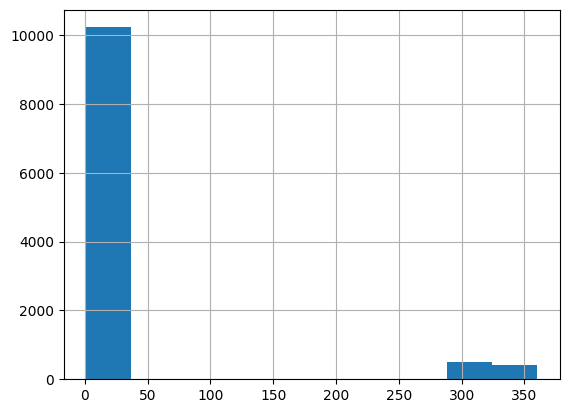

In [8]:
# city_counts = df['direction_peak_wind_speed'].value_counts()
# plt.figure(figsize=(20, 10))
# plt.hist(city_counts.index, city_counts.values, color='teal')
# plt.title('Rental Listings by City')
# plt.xlabel('City')
# plt.ylabel('Number of Listings')
# plt.tight_layout()
df['direction_peak_wind_speed'].hist()
plt.show()

In [9]:
df['direction_peak_wind_speed'].skew()

3.0347045071430854

In [10]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['direction_peak_wind_speed']])
df[['direction_peak_wind_speed']] = imputer.transform(df[['direction_peak_wind_speed']])

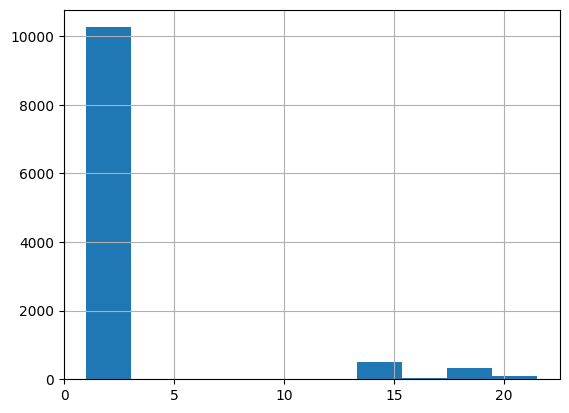

In [11]:
df['max_wind_speed'].hist()
plt.show()

In [12]:
df['max_wind_speed'].skew()

3.182362239243895

In [13]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['max_wind_speed']])
df[['max_wind_speed']] = imputer.transform(df[['max_wind_speed']])

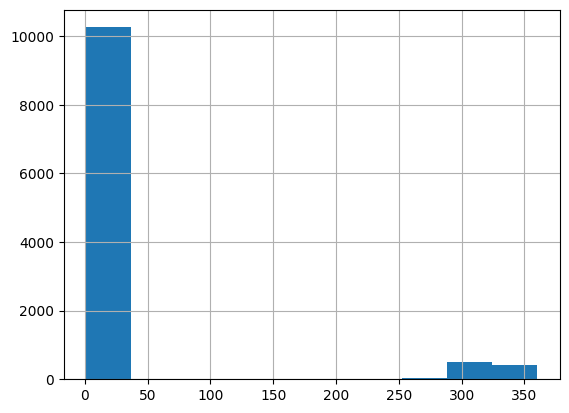

In [14]:
df['direction_max_wind_speed'].hist()
plt.show()

In [15]:
df['direction_max_wind_speed'].skew()

3.016632214473574

In [16]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['direction_max_wind_speed']])
df[['direction_max_wind_speed']] = imputer.transform(df[['direction_max_wind_speed']])

<Axes: >

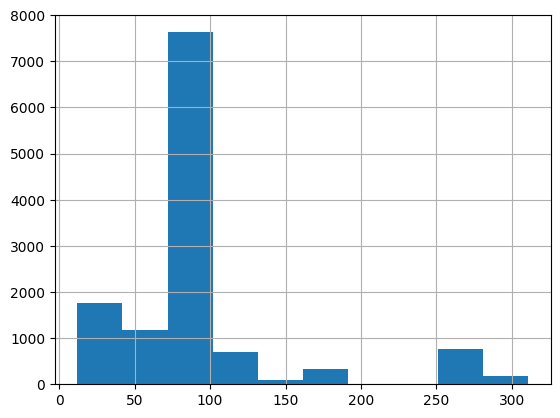

In [17]:
df['days_with_fog'].hist()


In [18]:
df['days_with_fog'].skew()

1.6187703518774261

In [19]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['days_with_fog']])
df[['days_with_fog']] = imputer.transform(df[['days_with_fog']])

<Axes: >

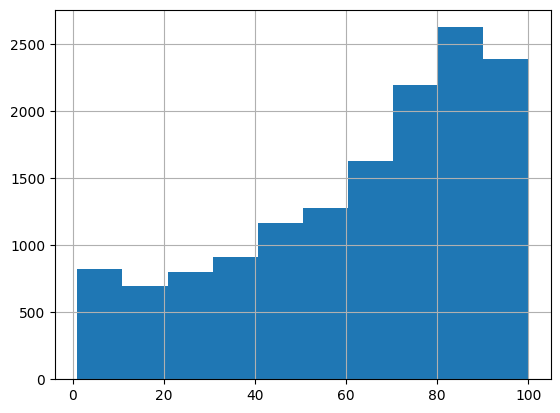

In [20]:
df['energy_star_rating'].hist()

In [21]:
df['energy_star_rating'].skew()

-0.6517258439153917

In [22]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['energy_star_rating']])
df[['energy_star_rating']] = imputer.transform(df[['energy_star_rating']])

<Axes: >

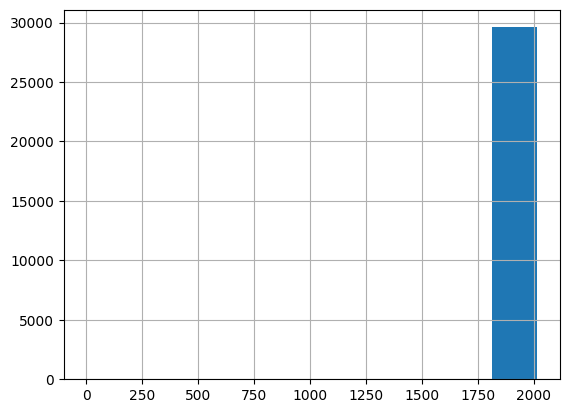

In [23]:
df['year_built'].hist()

In [24]:
df['year_built'].skew()

-17.41985694881333

In [25]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='median')
# strategy = 'median', 'mean', 'constant', 'most_frequent'
imputer.fit(df[['year_built']])
df[['year_built']] = imputer.transform(df[['year_built']])

In [26]:
df.isnull().sum().sort_values(ascending=False).head()

Year_Factor      0
may_avg_temp     0
june_min_temp    0
june_avg_temp    0
june_max_temp    0
dtype: int64

In [27]:
df.columns

Index(['Year_Factor', 'State_Factor', 'building_class', 'facility_type',
       'floor_area', 'year_built', 'energy_star_rating', 'ELEVATION',
       'january_min_temp', 'january_avg_temp', 'january_max_temp',
       'february_min_temp', 'february_avg_temp', 'february_max_temp',
       'march_min_temp', 'march_avg_temp', 'march_max_temp', 'april_min_temp',
       'april_avg_temp', 'april_max_temp', 'may_min_temp', 'may_avg_temp',
       'may_max_temp', 'june_min_temp', 'june_avg_temp', 'june_max_temp',
       'july_min_temp', 'july_avg_temp', 'july_max_temp', 'august_min_temp',
       'november_max_temp', 'december_min_temp', 'days_below_10F',
       'days_below_0F', 'days_above_80F', 'direction_max_wind_speed',
       'direction_peak_wind_speed', 'max_wind_speed', 'days_with_fog',
       'site_eui', 'id'],
      dtype='object')

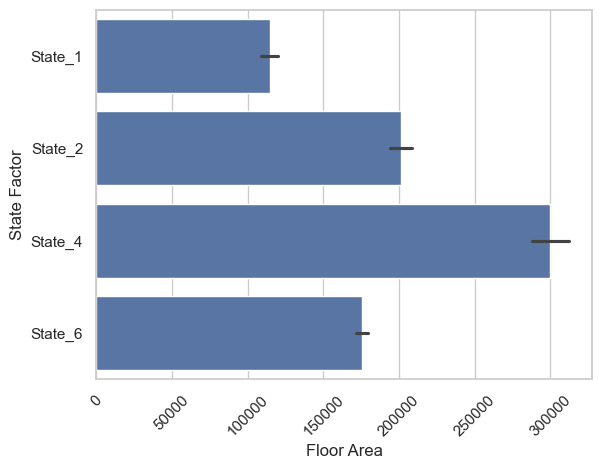

In [28]:
sns.set(style='whitegrid' )
sns.barplot(data=df , x='floor_area' , y='State_Factor')
plt.title('', fontsize=16, color='blue')
plt.xlabel('Floor Area')
plt.ylabel('State Factor')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='march_avg_temp', ylabel='june_avg_temp'>

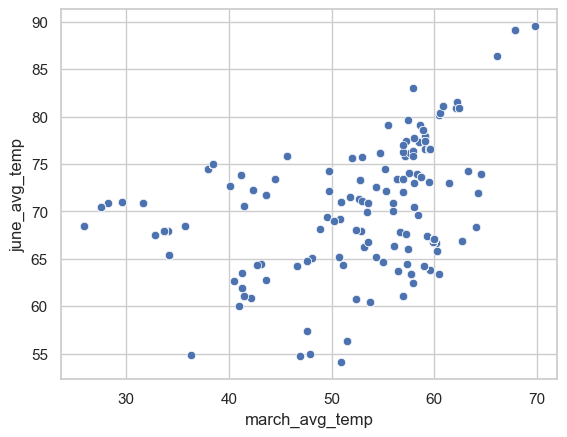

In [29]:
sns.scatterplot(data = df , x='march_avg_temp' , y='june_avg_temp')

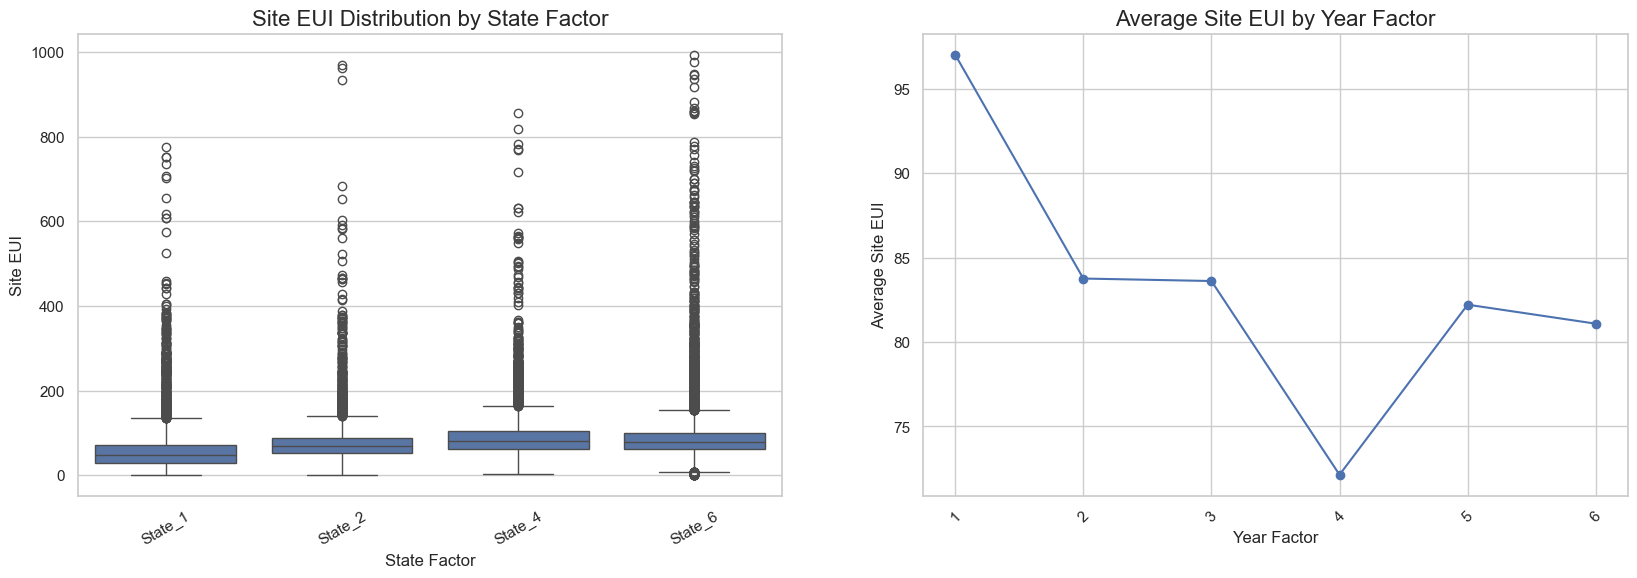

In [30]:
plt.figure(figsize=(20, 6))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='State_Factor', y='site_eui', ax=plt.gca())
plt.title('Site EUI Distribution by State Factor', fontsize=16)
plt.xlabel('State Factor')
plt.ylabel('Site EUI')
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
df.groupby('Year_Factor')['site_eui'].mean().plot(
    kind='line', marker='o', ax=plt.gca()
)
plt.title('Average Site EUI by Year Factor', fontsize=16)
plt.xlabel('Year Factor')
plt.ylabel('Average Site EUI')
plt.xticks(rotation=45)

# plt.tight_layout()
plt.show()

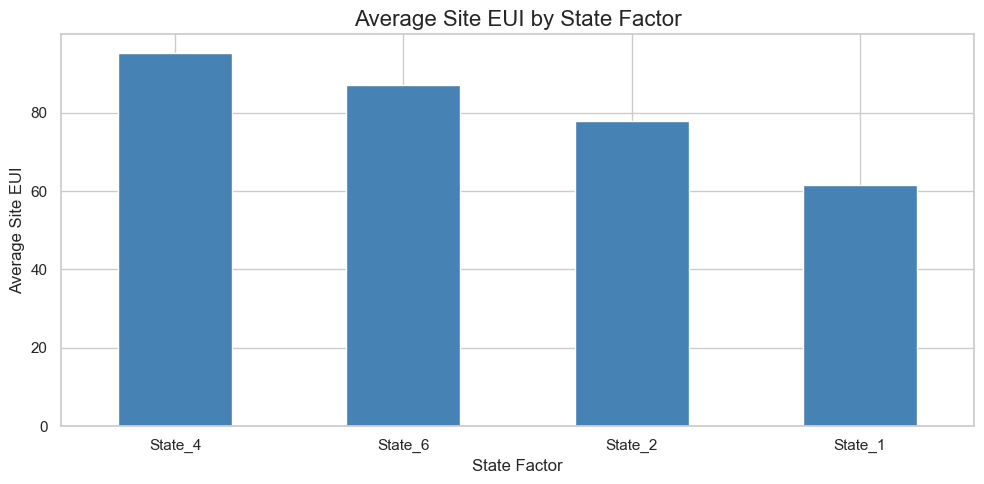

In [31]:
df_tot = df.groupby('State_Factor')['site_eui'].mean().sort_values(ascending=False)
ax = df_tot.plot(kind='bar', figsize=(10, 5), color='steelblue')
ax.set_title('Average Site EUI by State Factor', fontsize=16)
ax.set_xlabel('State Factor')
ax.set_ylabel('Average Site EUI')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
df.head(15)

,Year_Factor,State_Factor,building_class,facility_type,floor_area,year_built,energy_star_rating,ELEVATION,january_min_temp,january_avg_temp,...,december_min_temp,days_below_10F,days_below_0F,days_above_80F,direction_max_wind_speed,direction_peak_wind_speed,max_wind_speed,days_with_fog,site_eui,id
0,1,State_1,Commercial,Grocery_store_or_food_market,61242.0,1942.0,11.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,248.682615,0
1,1,State_1,Commercial,Warehouse_Distribution_or_Shipping_center,274000.0,1955.0,45.0,1.8,36,50.5,...,36,0,0,14,1.0,1.0,1.0,12.0,26.500150,1
2,1,State_1,Commercial,Retail_Enclosed_mall,280025.0,1951.0,97.0,1.8,36,50.5,...,36,0,0,14,1.0,1.0,1.0,12.0,24.693619,2
3,1,State_1,Commercial,Education_Other_classroom,55325.0,1980.0,46.0,1.8,36,50.5,...,36,0,0,14,1.0,1.0,1.0,12.0,48.406926,3
4,1,State_1,Commercial,Warehouse_Nonrefrigerated,66000.0,1985.0,100.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,3.899395,4
5,1,State_1,Commercial,Warehouse_Selfstorage,119900.0,1956.0,70.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,6.597715,5
6,1,State_1,Commercial,Warehouse_Nonrefrigerated,91367.0,1982.0,56.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,12.817841,6
7,1,State_1,Commercial,Warehouse_Nonrefrigerated,50422.0,1947.0,99.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,22.392014,7
8,1,State_1,Commercial,Office_Uncategorized,122020.0,1929.0,98.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,28.199578,8
9,1,State_1,Commercial,Office_Uncategorized,102612.0,1979.0,83.0,2.4,36,50.5,...,36,0,0,14,1.0,1.0,1.0,93.0,29.515952,9


In [33]:
df.drop(['id','direction_max_wind_speed', 'direction_peak_wind_speed', 'max_wind_speed' , 'days_with_fog'] , axis=1 , inplace= True)

In [34]:
df.reset_index(drop=True, inplace=True)

In [35]:
df.head(10)

,Year_Factor,State_Factor,building_class,facility_type,floor_area,year_built,energy_star_rating,ELEVATION,january_min_temp,january_avg_temp,...,july_min_temp,july_avg_temp,july_max_temp,august_min_temp,november_max_temp,december_min_temp,days_below_10F,days_below_0F,days_above_80F,site_eui
0,1,State_1,Commercial,Grocery_store_or_food_market,61242.0,1942.0,11.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,248.682615
1,1,State_1,Commercial,Warehouse_Distribution_or_Shipping_center,274000.0,1955.0,45.0,1.8,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,26.500150
2,1,State_1,Commercial,Retail_Enclosed_mall,280025.0,1951.0,97.0,1.8,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,24.693619
3,1,State_1,Commercial,Education_Other_classroom,55325.0,1980.0,46.0,1.8,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,48.406926
4,1,State_1,Commercial,Warehouse_Nonrefrigerated,66000.0,1985.0,100.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,3.899395
5,1,State_1,Commercial,Warehouse_Selfstorage,119900.0,1956.0,70.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,6.597715
6,1,State_1,Commercial,Warehouse_Nonrefrigerated,91367.0,1982.0,56.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,12.817841
7,1,State_1,Commercial,Warehouse_Nonrefrigerated,50422.0,1947.0,99.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,22.392014
8,1,State_1,Commercial,Office_Uncategorized,122020.0,1929.0,98.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,28.199578
9,1,State_1,Commercial,Office_Uncategorized,102612.0,1979.0,83.0,2.4,36,50.5,...,52,62.725806,84,52,72,36,0,0,14,29.515952


In [36]:
df.select_dtypes(include=['object']).columns

Index(['State_Factor', 'building_class', 'facility_type'], dtype='object')

In [37]:
df.isnull().sum().sort_values(ascending=False)

Year_Factor           0
State_Factor          0
may_min_temp          0
may_avg_temp          0
may_max_temp          0
june_min_temp         0
june_avg_temp         0
june_max_temp         0
july_min_temp         0
july_avg_temp         0
july_max_temp         0
august_min_temp       0
november_max_temp     0
december_min_temp     0
days_below_10F        0
days_below_0F         0
days_above_80F        0
april_max_temp        0
april_avg_temp        0
april_min_temp        0
january_min_temp      0
building_class        0
facility_type         0
floor_area            0
year_built            0
energy_star_rating    0
ELEVATION             0
january_avg_temp      0
march_max_temp        0
january_max_temp      0
february_min_temp     0
february_avg_temp     0
february_max_temp     0
march_min_temp        0
march_avg_temp        0
site_eui              0
dtype: int64

In [38]:
from sklearn.preprocessing import OneHotEncoder

In [39]:
onhot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [40]:
temp = onhot.fit_transform(df[['building_class']])
df = pd.concat([df,temp],axis=1)

In [41]:
temp = onhot.fit_transform(df[['facility_type']])
df = pd.concat([df,temp],axis=1)

In [42]:
df.head()

,Year_Factor,State_Factor,building_class,facility_type,floor_area,year_built,energy_star_rating,ELEVATION,january_min_temp,january_avg_temp,...,facility_type_Retail_Strip_shopping_mall,facility_type_Retail_Uncategorized,facility_type_Retail_Vehicle_dealership_showroom,facility_type_Service_Drycleaning_or_Laundry,facility_type_Service_Uncategorized,facility_type_Service_Vehicle_service_repair_shop,facility_type_Warehouse_Distribution_or_Shipping_center,facility_type_Warehouse_Nonrefrigerated,facility_type_Warehouse_Refrigerated,facility_type_Warehouse_Selfstorage
0,1,State_1,Commercial,Grocery_store_or_food_market,61242.0,1942.0,11.0,2.4,36,50.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,State_1,Commercial,Warehouse_Distribution_or_Shipping_center,274000.0,1955.0,45.0,1.8,36,50.5,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1,State_1,Commercial,Retail_Enclosed_mall,280025.0,1951.0,97.0,1.8,36,50.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,State_1,Commercial,Education_Other_classroom,55325.0,1980.0,46.0,1.8,36,50.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1,State_1,Commercial,Warehouse_Nonrefrigerated,66000.0,1985.0,100.0,2.4,36,50.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [43]:
df.drop(['facility_type','building_class'] , axis = 1 , inplace=True )

In [44]:
df.reset_index(drop=True, inplace=True)

In [45]:
from sklearn.model_selection import train_test_split

In [46]:
X = df.drop('State_Factor',axis = 1)
y = df['State_Factor']

In [47]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (24885, 91)  y_train =  (24885,)
X_test  =  (6222, 91)  y_test  =  (6222,)


In [48]:
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0,1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

In [49]:
y_train.head()

13370    State_4
19496    State_6
3438     State_1
5427     State_2
103      State_1
Name: State_Factor, dtype: object

In [50]:
y_test.head()

408      State_1
21287    State_6
4534     State_1
22041    State_6
8834     State_2
Name: State_Factor, dtype: object

In [51]:
from sklearn.linear_model import LinearRegression

In [52]:
from sklearn.linear_model import LogisticRegression

In [53]:
model = LogisticRegression(
    
    C = 1.0,
    # solver='lbfgs',
    max_iter=1000,
    fit_intercept=True,
)

In [54]:
model.fit(X_train , y_train)

LogisticRegression(max_iter=1000)

In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score , classification_report

In [56]:
y_pred = model.predict(X_test)

In [57]:
score = accuracy_score(y_test , y_pred)
print(score)

0.9998392799742848


In [58]:
pre = precision_score(y_test, y_pred, average='macro')
print(pre)

0.9999266216612857


In [59]:
recall = recall_score(y_test, y_pred, average='macro')
print(recall)

0.999751491053678


In [60]:
clas = classification_report(y_test , y_pred)
print(clas)

              precision    recall  f1-score   support

     State_1       1.00      1.00      1.00       959
     State_2       1.00      1.00      1.00      1006
     State_4       1.00      1.00      1.00       851
     State_6       1.00      1.00      1.00      3406

    accuracy                           1.00      6222
   macro avg       1.00      1.00      1.00      6222
weighted avg       1.00      1.00      1.00      6222



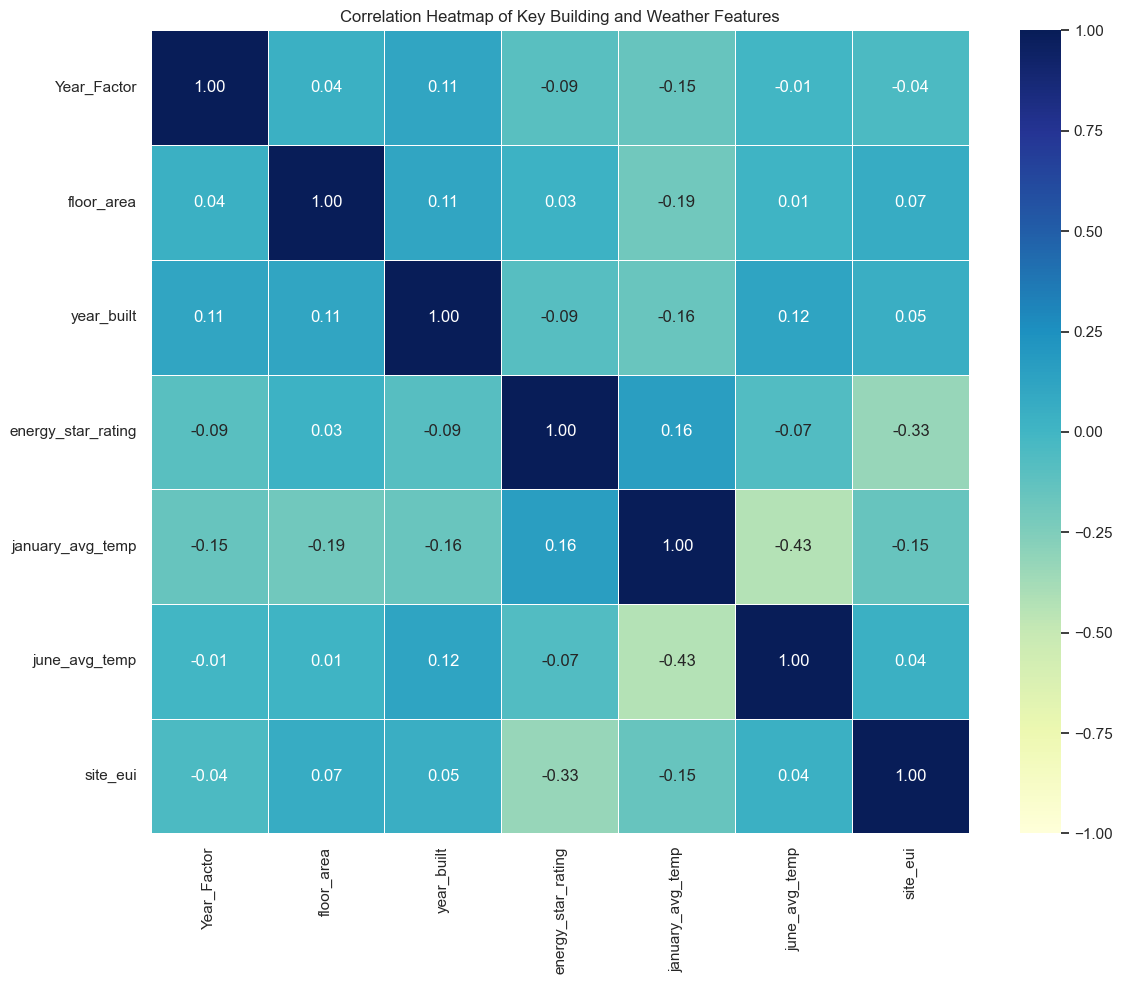

In [61]:
# A cleaner heatmap using meaningful building and weather variables
selected_columns = [
    'Year_Factor', 'floor_area', 'year_built', 'energy_star_rating',
    'january_avg_temp', 'june_avg_temp',
 'site_eui'
]

heatmap_df = df[selected_columns].dropna()
heatmap_corr = heatmap_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    heatmap_corr,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap of Key Building and Weather Features')
plt.tight_layout()
plt.show()


In [62]:
from sklearn.neighbors import KNeighborsClassifier


In [63]:
from sklearn. metrics import accuracy_score, precision_score, recall_score, f1_score

In [64]:
model = KNeighborsClassifier(n_neighbors=5, metric='minkowski',p=1) # metric = 'euclidean'
model.fit(X_train,y_train)
y_pred_train= model.predict(X_train)
y_predtest=model.predict(X_test)
AcC_Train = accuracy_score(y_train, y_pred_train)

In [65]:
score = accuracy_score(y_train , y_pred_train)
print(score)

0.9997990757484428


In [66]:
pre = precision_score(y_train ,y_pred_train, average='macro')
print(pre)

0.9999084181991355


In [67]:
recall = recall_score(y_train, y_pred_train, average='macro')
print(recall)

0.9996765847347995


In [68]:
clas = classification_report(y_train , y_pred_train)
print(clas)

              precision    recall  f1-score   support

     State_1       1.00      1.00      1.00      3927
     State_2       1.00      1.00      1.00      3865
     State_4       1.00      1.00      1.00      3449
     State_6       1.00      1.00      1.00     13644

    accuracy                           1.00     24885
   macro avg       1.00      1.00      1.00     24885
weighted avg       1.00      1.00      1.00     24885



In [69]:
from sklearn.metrics import r2_score , mean_absolute_error , mean_squared_error


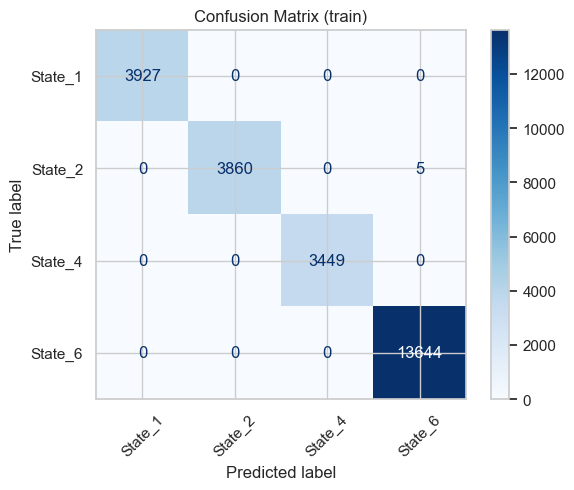

In [70]:
from sklearn.metrics import ConfusionMatrixDisplay

# target is categorical, so use a confusion matrix instead of a regression metric (R2)
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train, xticks_rotation=45, cmap='Blues')
plt.title('Confusion Matrix (train)')
plt.show()